# 03 - Anomaly Detection Modeling

**Deliverables**: `models/best_model.pkl`, `models/predictions.pkl`, `models/model_comparison.csv`, `reports/model_evaluation.md`

In [1]:
import sys
sys.path.insert(0, '../')
import pickle
from pathlib import Path
import pandas as pd
import numpy as np
import joblib
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import IsolationForest
from sklearn.neighbors import LocalOutlierFactor
from sklearn.metrics import (roc_auc_score, average_precision_score, f1_score,
                             precision_score, recall_score, precision_recall_curve,
                             brier_score_loss)
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
import shap
print('Environment ready')

Environment ready


/home/user/.local/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
pip install shap

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


## 1. Load Data

In [3]:
META = {'target', 'label', 'anomaly_type', 'anomaly_type_target',
        'event_timestamp', 'timestamp', 'src_ip', 'dst_ip', 'protocol',
        'status', 'status_clean', 'source_record_id', 'composite_key', 'prev_ts'}
try:
    feature_cols = joblib.load('../features/feature_cols.joblib')
    print(f'Loaded {len(feature_cols)} features from joblib')
except FileNotFoundError:
    feature_cols = None

def load_split(name):
    df = pd.read_parquet(f'../features/{name}.parquet')
    y = df['target'].reset_index(drop=True)
    if feature_cols is not None:
        keep = [c for c in feature_cols if c in df.columns]
        X = df[keep].fillna(0).reset_index(drop=True)
    else:
        drop = [c for c in META if c in df.columns]
        X = df.drop(columns=drop).select_dtypes(include=[np.number]).fillna(0).reset_index(drop=True)
    return X, y

X_train, y_train = load_split('train')
X_val,   y_val   = load_split('val')
X_test,  y_test  = load_split('test')
common = X_train.columns.intersection(X_val.columns).intersection(X_test.columns)
X_train, X_val, X_test = X_train[common], X_val[common], X_test[common]
print(f'Features: {len(common)}')
print(f'Train={X_train.shape}, Val={X_val.shape}, Test={X_test.shape}')
print(f'Malicious rate — train={y_train.mean():.3f}, val={y_val.mean():.3f}, test={y_test.mean():.3f}')

Loaded 36 features from joblib
Features: 36
Train=(6275, 36), Val=(1614, 36), Test=(1548, 36)
Malicious rate — train=0.049, val=0.048, test=0.050


## 2. Unsupervised Baselines

In [4]:
iso = IsolationForest(n_estimators=200, contamination=0.05, random_state=42, n_jobs=-1)
iso.fit(X_train)
iso_threshold = np.percentile(-iso.score_samples(X_train), 95)
iso_scores_val = -iso.score_samples(X_val)
iso_scores_test = -iso.score_samples(X_test)
iso_pred_val = (iso_scores_val > iso_threshold).astype(int)
iso_pred_test = (iso_scores_test > iso_threshold).astype(int)
print(f'IF threshold: {iso_threshold:.3f}, val positive rate: {iso_pred_val.mean():.3f}')

n_lof = min(5000, len(X_train))
idx_lof = np.random.RandomState(42).choice(len(X_train), n_lof, replace=False)
lof = LocalOutlierFactor(n_neighbors=20, contamination=0.05, novelty=True, n_jobs=-1)
lof.fit(X_train.iloc[idx_lof])
lof_threshold = np.percentile(-lof.score_samples(X_train.iloc[idx_lof]), 95)
lof_scores_val = -lof.score_samples(X_val)
lof_scores_test = -lof.score_samples(X_test)
lof_pred_val = (lof_scores_val > lof_threshold).astype(int)
lof_pred_test = (lof_scores_test > lof_threshold).astype(int)
print(f'LOF threshold: {lof_threshold:.3f}')

IF threshold: 0.562, val positive rate: 0.086
LOF threshold: 1.106


/home/user/.local/lib/python3.10/site-packages/sklearn/utils/validation.py:2749: UserWarning: X does not have valid feature names, but LocalOutlierFactor was fitted with feature names
  warnings.warn(
/home/user/.local/lib/python3.10/site-packages/sklearn/utils/validation.py:2749: UserWarning: X does not have valid feature names, but LocalOutlierFactor was fitted with feature names
  warnings.warn(
/home/user/.local/lib/python3.10/site-packages/sklearn/utils/validation.py:2749: UserWarning: X does not have valid feature names, but LocalOutlierFactor was fitted with feature names
  warnings.warn(


## 3. Supervised Models

In [5]:
lr = LogisticRegression(class_weight='balanced', max_iter=1000, C=1.0, random_state=42, n_jobs=-1)
lr.fit(X_train, y_train)
lr_proba_val = lr.predict_proba(X_val)[:, 1]
lr_proba_test = lr.predict_proba(X_test)[:, 1]
lr_pred_val = (lr_proba_val > 0.5).astype(int)
lr_pred_test = (lr_proba_test > 0.5).astype(int)
print('LogisticRegression trained')

# scale_pos_weight = float((y_train == 0).sum()) / max((y_train == 1).sum(), 1)
# xgb = XGBClassifier(n_estimators=500, max_depth=6, learning_rate=0.05,
#                     subsample=0.8, colsample_bytree=0.8,
#                     scale_pos_weight=scale_pos_weight,
#                     random_state=42, n_jobs=-1, eval_metric='aucpr', verbosity=0)
# xgb.fit(X_train, y_train, eval_set=[(X_val, y_val)], early_stopping_rounds=50)
# xgb_proba_val = xgb.predict_proba(X_val)[:, 1]
# xgb_proba_test = xgb.predict_proba(X_test)[:, 1]
# xgb_pred_val = (xgb_proba_val > 0.5).astype(int)
# xgb_pred_test = (xgb_proba_test > 0.5).astype(int)
# print(f'XGBoost trained (best_iter={getattr(xgb, "best_iteration", "?")})')

scale_pos_weight = float((y_train == 0).sum()) / max((y_train == 1).sum(), 1)
xgb = XGBClassifier(
    n_estimators=500, max_depth=6, learning_rate=0.05,
    subsample=0.8, colsample_bytree=0.8,
    scale_pos_weight=scale_pos_weight,
    early_stopping_rounds=50,          # <-- moved here
    random_state=42, n_jobs=-1, eval_metric='aucpr', verbosity=0,
)
xgb.fit(X_train, y_train, eval_set=[(X_val, y_val)], verbose=False)
xgb_proba_val = xgb.predict_proba(X_val)[:, 1]
xgb_proba_test = xgb.predict_proba(X_test)[:, 1]
xgb_pred_val = (xgb_proba_val > 0.5).astype(int)
xgb_pred_test = (xgb_proba_test > 0.5).astype(int)
print(f'XGBoost trained (best_iter={getattr(xgb, "best_iteration", "?")})')

lgb = LGBMClassifier(n_estimators=500, max_depth=6, learning_rate=0.05,
                     subsample=0.8, colsample_bytree=0.8, class_weight='balanced',
                     random_state=42, n_jobs=-1, verbosity=-1)
lgb.fit(X_train, y_train, eval_set=[(X_val, y_val)], eval_metric='average_precision')
lgb_proba_val = lgb.predict_proba(X_val)[:, 1]
lgb_proba_test = lgb.predict_proba(X_test)[:, 1]
lgb_pred_val = (lgb_proba_val > 0.5).astype(int)
lgb_pred_test = (lgb_proba_test > 0.5).astype(int)
print('LightGBM trained')

LogisticRegression trained
XGBoost trained (best_iter=33)


/home/user/.local/lib/python3.10/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


LightGBM trained


## 4. Evaluation

In [6]:
def evaluate_model(y_true, y_pred, y_proba, name):
    y_true = pd.Series(y_true).reset_index(drop=True)
    y_pred = pd.Series(y_pred).reset_index(drop=True)
    y_proba = np.asarray(y_proba).ravel()

    m = {
        'model': name,
        'roc_auc': roc_auc_score(y_true, y_proba),
        'pr_auc': average_precision_score(y_true, y_proba),
        'f1': f1_score(y_true, y_pred, zero_division=0),
        'precision': precision_score(y_true, y_pred, zero_division=0),
        'recall': recall_score(y_true, y_pred, zero_division=0),
    }

    # Brier requires probabilities in [0, 1]; skip for raw anomaly scores
    if y_proba.min() >= 0 and y_proba.max() <= 1:
        m['brier'] = brier_score_loss(y_true, y_proba)
    else:
        m['brier'] = np.nan

    for k_pct in [0.01, 0.05, 0.10]:
        k = max(1, int(len(y_proba) * k_pct))
        top = np.argsort(y_proba)[-k:]
        m[f'precision@{int(k_pct*100)}%'] = precision_score(y_true.iloc[top], y_pred.iloc[top], zero_division=0)
        m[f'recall@{int(k_pct*100)}%'] = recall_score(y_true.iloc[top], y_pred.iloc[top], zero_division=0)

    return m


models_val = {
    'IsolationForest': (iso_pred_val, iso_scores_val),
    'LOF': (lof_pred_val, lof_scores_val),
    'LogisticRegression': (lr_pred_val, lr_proba_val),
    'XGBoost': (xgb_pred_val, xgb_proba_val),
    'LightGBM': (lgb_pred_val, lgb_proba_val),
}
val_df = pd.DataFrame([evaluate_model(y_val, p, pr, n) for n, (p, pr) in models_val.items()])
print(val_df[['model', 'pr_auc', 'roc_auc', 'f1', 'precision', 'recall']].to_string(index=False))

             model   pr_auc  roc_auc       f1  precision   recall
   IsolationForest 0.045311 0.484203 0.046512   0.036232 0.064935
               LOF 0.053554 0.506396 0.072727   0.055944 0.103896
LogisticRegression 0.048750 0.497689 0.084253   0.045652 0.545455
           XGBoost 0.076391 0.508682 0.073434   0.044041 0.220779
          LightGBM 0.046976 0.490372 0.037736   0.036585 0.038961


## 5. Threshold Optimization (on validation)

In [7]:
prec, rec, thr = precision_recall_curve(y_val, xgb_proba_val)
f1_scores = 2 * (prec * rec) / (prec + rec + 1e-10)
best_idx = int(np.argmax(f1_scores[:-1]))
optimal_threshold = float(thr[best_idx])
print(f'Optimal threshold (F1 on val): {optimal_threshold:.4f}')
print(f'Precision={prec[best_idx]:.4f}, Recall={rec[best_idx]:.4f}, F1={f1_scores[best_idx]:.4f}')

xgb_pred_test_opt = (xgb_proba_test > optimal_threshold).astype(int)
test_metrics = evaluate_model(y_test, xgb_pred_test_opt, xgb_proba_test, 'XGBoost_optimal')
print('\nTest metrics (optimal threshold):')
for k, v in test_metrics.items():
    if k != 'model' and isinstance(v, (int, float, np.floating)):
        print(f'  {k}: {v:.4f}')

Optimal threshold (F1 on val): 0.4234
Precision=0.0538, Recall=0.5714, F1=0.0983

Test metrics (optimal threshold):
  roc_auc: 0.4898
  pr_auc: 0.0560
  f1: 0.0925
  precision: 0.0508
  recall: 0.5195
  brier: 0.1999
  precision@1%: 0.0667
  recall@1%: 1.0000
  precision@5%: 0.0649
  recall@5%: 1.0000
  precision@10%: 0.0519
  recall@10%: 1.0000


## 6. Subgroup Analysis by Anomaly Type

In [8]:
test_full = pd.read_parquet('../features/test.parquet').reset_index(drop=True)
assert len(test_full) == len(xgb_proba_test), 'row alignment broken'
test_full['proba'] = xgb_proba_test
test_full['pred'] = xgb_pred_test_opt
print('=== Performance by Anomaly Type ===')
for atype in test_full['anomaly_type'].dropna().unique():
    if atype == '':
        continue
    sub = test_full[test_full['anomaly_type'] == atype]
    if len(sub) < 2 or sub['target'].nunique() < 2:
        print(f'  {atype}: n={len(sub)} (single class)')
        continue
    auc = roc_auc_score(sub['target'], sub['proba'])
    pr = average_precision_score(sub['target'], sub['proba'])
    print(f'  {atype}: n={len(sub)}, ROC-AUC={auc:.4f}, PR-AUC={pr:.4f}')

=== Performance by Anomaly Type ===
  ddos: n=17, ROC-AUC=0.4000, PR-AUC=0.1394
  data_exfil: n=10 (single class)
  port_scan: n=11, ROC-AUC=0.5000, PR-AUC=0.1667
  brute_force: n=20, ROC-AUC=0.5556, PR-AUC=0.1548


## 7. SHAP Explainability

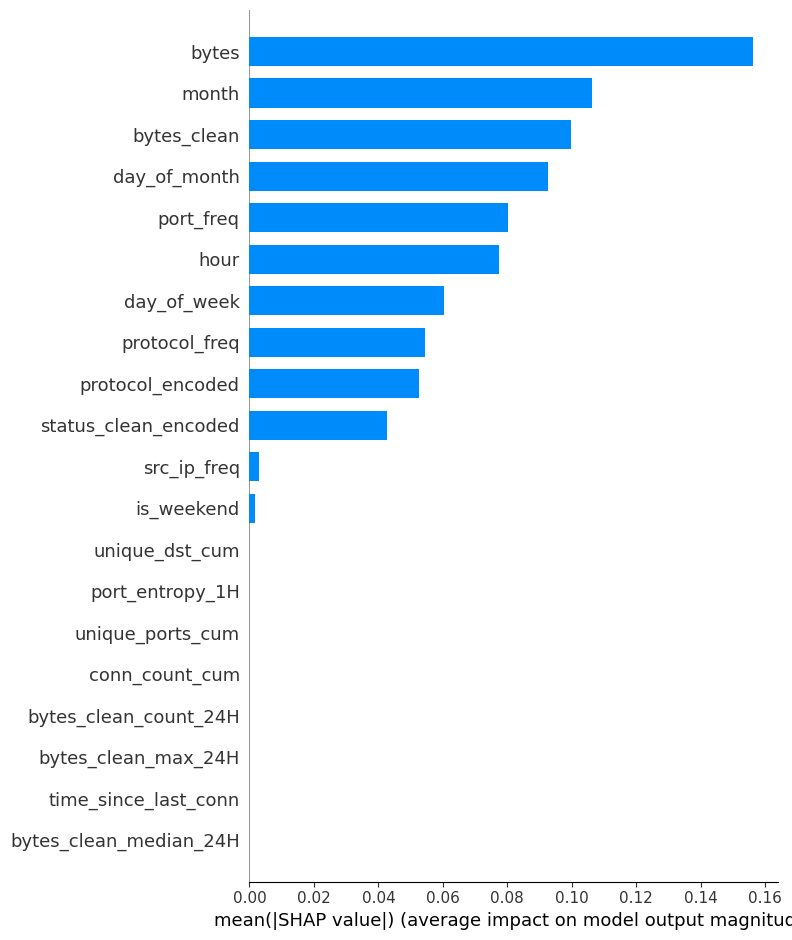

In [9]:
explainer = shap.TreeExplainer(xgb)
sample = X_val.sample(n=min(1000, len(X_val)), random_state=42)
shap_vals = explainer.shap_values(sample)
shap.summary_plot(shap_vals, sample, plot_type='bar', show=True)

In [10]:
pip install "xgboost==2.1.0" --force-reinstall

Defaulting to user installation because normal site-packages is not writeable
  Using cached xgboost-2.1.0-py3-none-manylinux_2_28_x86_64.whl (153.9 MB)
  Using cached nvidia_nccl_cu12-2.32.3-py3-none-manylinux_2_27_x86_64.whl (351.5 MB)
  Using cached numpy-2.2.6-cp310-cp310-manylinux_2_17_x86_64.manylinux2014_x86_64.whl (16.8 MB)
  Using cached scipy-1.15.3-cp310-cp310-manylinux_2_17_x86_64.manylinux2014_x86_64.whl (37.7 MB)
  Attempting uninstall: nvidia-nccl-cu12
    Found existing installation: nvidia-nccl-cu12 2.32.3
    Uninstalling nvidia-nccl-cu12-2.32.3:
      Successfully uninstalled nvidia-nccl-cu12-2.32.3
  Attempting uninstall: numpy
    Found existing installation: numpy 2.2.6
    Uninstalling numpy-2.2.6:
      Successfully uninstalled numpy-2.2.6
  Attempting uninstall: scipy
    Found existing installation: scipy 1.15.3
    Uninstalling scipy-1.15.3:
      Successfully uninstalled scipy-1.15.3
  Attempting uninstall: xgboost
    Found existing installation: xgboost 2.

## 8. Save Model, Predictions, Comparison

In [11]:
Path('../models').mkdir(parents=True, exist_ok=True)
joblib.dump(xgb, '../models/best_model.pkl')
joblib.dump({'threshold': optimal_threshold, 'model_type': 'XGBoost'}, '../models/model_metadata.pkl')
with open('../models/predictions.pkl', 'wb') as f:
    pickle.dump({'val_proba': xgb_proba_val, 'test_proba': xgb_proba_test,
                 'y_val': y_val, 'y_test': y_test,
                 'optimal_threshold': optimal_threshold}, f)

models_test = {'IsolationForest': (iso_pred_test, iso_scores_test),
               'LOF': (lof_pred_test, lof_scores_test),
               'LogisticRegression': (lr_pred_test, lr_proba_test),
               'XGBoost': (xgb_pred_test, xgb_proba_test),
               'LightGBM': (lgb_pred_test, lgb_proba_test),
               'XGBoost_optimal': (xgb_pred_test_opt, xgb_proba_test)}
comparison_df = pd.DataFrame([evaluate_model(y_test, p, pr, n) for n, (p, pr) in models_test.items()])
comparison_df.to_csv('../models/model_comparison.csv', index=False)
print('Saved: best_model.pkl, predictions.pkl, model_comparison.csv')
print(comparison_df[['model', 'pr_auc', 'roc_auc', 'f1', 'precision', 'recall']].to_string(index=False))

lines = ['# Model Evaluation Report', '',
         '## Test-Set Comparison', '',
         comparison_df[['model', 'pr_auc', 'roc_auc', 'f1', 'precision', 'recall', 'brier']].to_markdown(index=False),
         '', '## Best Model: XGBoost',
         f'- Optimal threshold (F1 on val): {optimal_threshold:.4f}',
         f'- Test PR-AUC: {test_metrics["pr_auc"]:.4f}',
         f'- Test ROC-AUC: {test_metrics["roc_auc"]:.4f}',
         f'- Test F1: {test_metrics["f1"]:.4f}',
         f'- Test Precision: {test_metrics["precision"]:.4f}',
         f'- Test Recall: {test_metrics["recall"]:.4f}',
         f'- Brier score: {test_metrics["brier"]:.4f}',
         '', '## Subgroup Performance']
for atype in test_full['anomaly_type'].dropna().unique():
    if atype == '':
        continue
    sub = test_full[test_full['anomaly_type'] == atype]
    if len(sub) < 2 or sub['target'].nunique() < 2:
        continue
    auc = roc_auc_score(sub['target'], sub['proba'])
    pr = average_precision_score(sub['target'], sub['proba'])
    lines.append(f'- **{atype}**: n={len(sub)}, ROC-AUC={auc:.4f}, PR-AUC={pr:.4f}')
Path('../reports').mkdir(parents=True, exist_ok=True)
Path('../reports/model_evaluation.md').write_text('\n'.join(lines), encoding='utf-8')
print('model_evaluation.md saved')

Saved: best_model.pkl, predictions.pkl, model_comparison.csv
             model   pr_auc  roc_auc       f1  precision   recall
   IsolationForest 0.045882 0.455676 0.061404   0.046358 0.090909
               LOF 0.046561 0.479420 0.029557   0.023810 0.038961
LogisticRegression 0.047265 0.462332 0.074656   0.040383 0.493506
           XGBoost 0.056038 0.489790 0.062370   0.037129 0.194805
          LightGBM 0.066565 0.520310 0.059880   0.055556 0.064935
   XGBoost_optimal 0.056038 0.489790 0.092486   0.050761 0.519481
model_evaluation.md saved


In [12]:
pip install tabulate

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.
